## Notebook to create a protoplanetary disk

### Initial conditions

In [1]:
import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [2]:
# Generating the binary system 

M_A = 1.0788 | units.Msun
M_B = 0.9092 | units.Msun
a = 23.299 | units.au
e = 0.51947
i = 79.243 | units.deg # how it is viewed from earth, unimportant until placing a disk
long_asc_node = 205.073 | units.deg # defines how orbital plane is rotated along LoS, also unimportant
arg_per = 231.519 | units.deg # defines where periapsis lies in orbital plane, unimportant
true_an = 180 | units.deg # stars start at apastron, i.e. furthest apart
primaries, secondaries = generate_binaries(M_A, M_B, a, e, true_anomaly=true_an, G=constants.G)

alpha_cen_A = primaries[0]
alpha_cen_B = secondaries[0]

alpha_cen_A.name = "Alpha_Centauri_A"
alpha_cen_B.name = "Alpha_Centauri_B"

system = Particles()
system.add_particle(alpha_cen_A)
system.add_particle(alpha_cen_B)
system.move_to_center()

print(system)
print(alpha_cen_A.x)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
  959126942773424567    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9548694197369827228    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16.1909547219 149597870691.0 * m


In [3]:
# Candidate planet is a gas giant orbiting Alpha Centauri A. We can start with a fully-formed Saturn mass planet and test orbital stability. 
# After orbital stability is established (hopefully): start with a core of 10-20 Mearth and simulate core accretion of gas to form a gas giant

# First, explore orbital stability of candidate gas giant 

M_embryo = 0.0123 | units.Mearth
a_embryo = 2 | units.au
e_embryo = 0.4 

stars, planets = generate_binaries(M_A, M_embryo, a_embryo, e_embryo, G=constants.G)
star = stars[0]
planet = planets[0]
planet.position -= star.position # planet position relative to star 
planet.velocity -= star.velocity # planet velocity relative to star

planet.position += system[0].position # absolute position
planet.velocity += system[0].velocity # absolute velocity 

planet.name = "Alpha_Centauri_Ab"

system.add_particle(planet)
system.move_to_center()
print(system)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
  959126942773424567    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9548694197369827228    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
11313518881153079659    3.693e-08  Alpha_Centauri_Ab    1.564e-22    9.779e-06    0.000e+00    1.739e+01   -1.983e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========


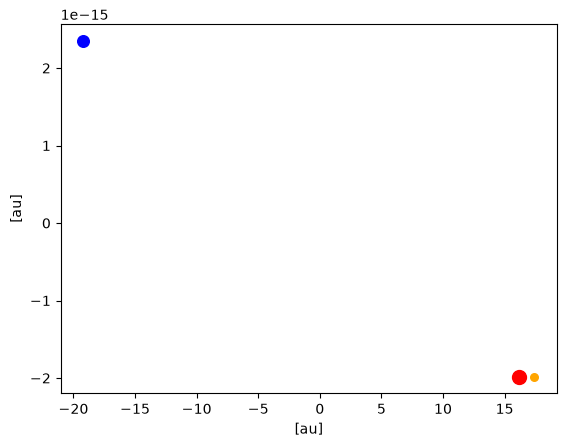

In [4]:
from amuse.plot import scatter

scatter(alpha_cen_A.x.in_(units.au), alpha_cen_A.y.in_(units.au), s=100, c='red')
scatter(alpha_cen_B.x.in_(units.au), alpha_cen_B.y.in_(units.au), s=70, c='blue')
scatter(planet.x.in_(units.au), planet.y.in_(units.au), s=30, c='orange')

In [5]:
from amuse.ext.protodisk import ProtoPlanetaryDisk

M_scale = system.mass.sum()
R_scale = a
converter = nbody_system.nbody_to_si(M_scale, R_scale)
Ndisk = 1000
Rin = 0.2 | units.au
Rout = 3 | units.au
rmin = Rin/R_scale
rmax = Rout/R_scale
Mdisk = 0.001 | units.Msun
disk = ProtoPlanetaryDisk(Ndisk,
                          convert_nbody=converter,
                          radius_min=rmin, # inner radius in units of reference length
                          radius_max=rmax, # outer radius in units of reference length
                          q_out=1, # Toomre Q parameter
                          discfraction=Mdisk/M_A).result
disk.name = "disk "
system.move_to_center()
disk.move_to_center()
print(disk.position.lengths().max().in_(units.au))
disk.position += alpha_cen_A.position # absolute coordinates of disk 
disk.velocity += alpha_cen_A.velocity # absolute velocity of disk
masses = Mdisk / float(Ndisk) # mass distributed equally 
disk.mass = masses
rho = 3.0 | (units.g / units.cm**3) # assume density of material
disk.radius = (disk.mass / (4 * rho))**(1./3.) # assign physical radius to each particle using formula
system.add_particles(disk)

print(system)


3.07685452727 au
                 key         mass         name       radius            u           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  (0.001 * m**3)**0.3333333333333333  m**2 * s**-2  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
  959126942773424567    1.079e+00  Alpha_Centauri_A    0.000e+00    0.000e+00    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9548694197369827228    9.092e-01  Alpha_Centauri_B    0.000e+00    0.000e+00   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
11313518881153079659    3.693e-08  Alpha_Centauri_Ab    0.000e+00    0.000e+00    1.564e-22    9.779e-06    0.0

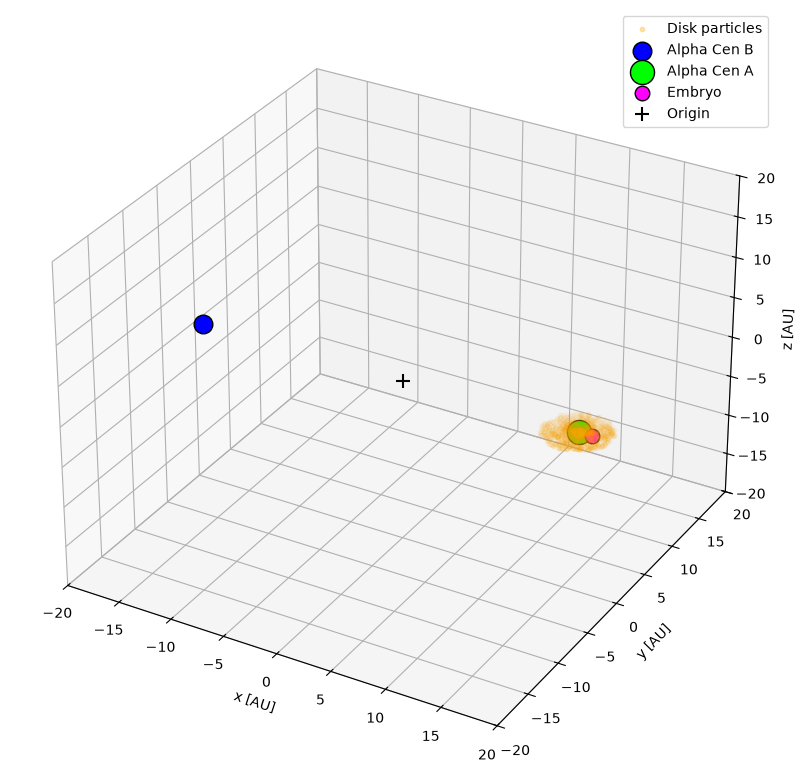

In [6]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           disk.z.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           alpha_cen_B.z.value_in(units.au),
           s=180, c="blue", edgecolors="black",
           depthshade=False, label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           alpha_cen_A.z.value_in(units.au),
           s=300, c="lime", edgecolors="black",
           depthshade=False, label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           planet.z.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
           depthshade=False, label="Embryo")

ax.scatter(0, 0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")
ax.legend()
plt.tight_layout()
plt.show()

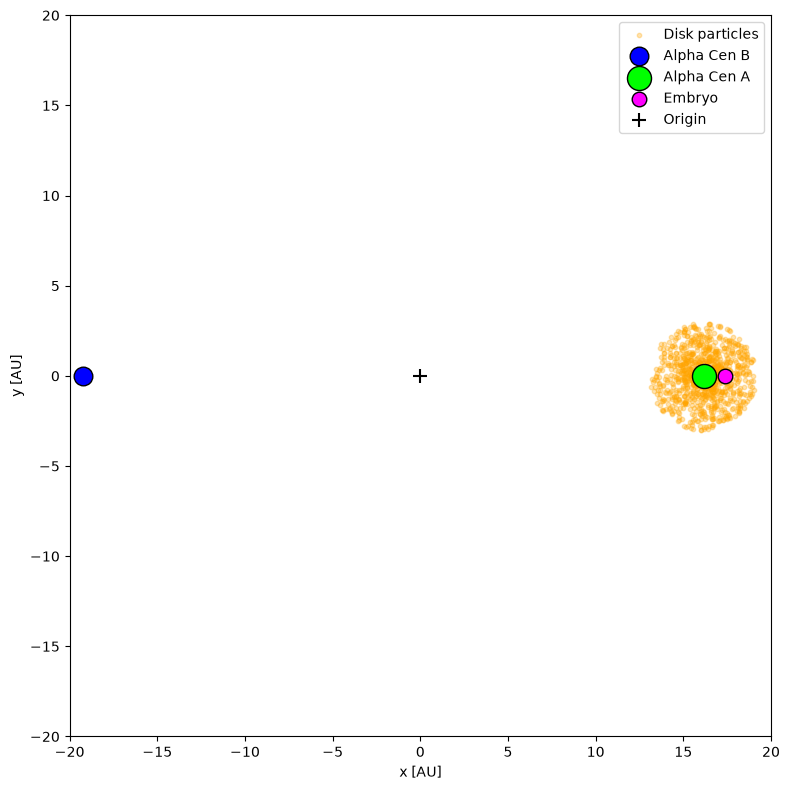

In [7]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot()

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           s=180, c="blue", edgecolors="black",
            label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           s=300, c="lime", edgecolors="black",
            label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
          label="Embryo")

ax.scatter(0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
from amuse.community.huayno.interface import Huayno

gravity = Huayno(converter)
gravity.particles.add_particles(system)
channel = gravity.particles.new_channel_to(system)


In [9]:
def evolve_gravity(gravity, system, channel, t_end):
    model_time = 0 | units.yr
    dt = 0.1 | units.yr
    time_saved = []
    xA, yA, zA = [], [], []
    xB, yB, zB = [], [], []
    xP, yP, zP = [], [], []
    xD, yD, zD = [], [], []


    while model_time < t_end:
        model_time += dt
        gravity.evolve_model(model_time)
        channel.copy()
        time_saved.append(model_time.value_in(units.yr))
        xA.append(system[0].x.value_in(units.au))
        yA.append(system[0].y.value_in(units.au))
        zA.append(system[0].z.value_in(units.au))
        xB.append(system[1].x.value_in(units.au))
        yB.append(system[1].y.value_in(units.au))
        zB.append(system[1].z.value_in(units.au))
        xP.append(system[2].x.value_in(units.au))
        yP.append(system[2].y.value_in(units.au))
        zP.append(system[2].z.value_in(units.au))
        xD.append(system[3:].x.value_in(units.au))
        yD.append(system[3:].y.value_in(units.au))
        zD.append(system[3:].z.value_in(units.au))

        print("time:", model_time)
        print(gravity.kinetic_energy)
        print(gravity.potential_energy)
        print(gravity.kinetic_energy + gravity.potential_energy)

    return time_saved, xA, yA, zA, xB, yB, zB, xP, yP, zP, xD, yD, zD

time_saved, xA, yA, zA, xB, yB, zB, xP, yP, zP, xD, yD, zD = evolve_gravity(gravity, system, channel, 100 | units.yr)

print(len(time_saved))
print(len(xA))

time: 0.1 yr
1.29680961712e+37 m**2 * kg * s**-2
-5.03624217097e+37 m**2 * kg * s**-2
-3.73943255385e+37 m**2 * kg * s**-2
time: 0.2 yr
1.27466748131e+37 m**2 * kg * s**-2
-5.01409998385e+37 m**2 * kg * s**-2
-3.73943250254e+37 m**2 * kg * s**-2
time: 0.30000000000000004 yr
1.26159710064e+37 m**2 * kg * s**-2
-5.00102959339e+37 m**2 * kg * s**-2
-3.73943249275e+37 m**2 * kg * s**-2
time: 0.4 yr
1.25380634467e+37 m**2 * kg * s**-2
-4.99323881074e+37 m**2 * kg * s**-2
-3.73943246606e+37 m**2 * kg * s**-2
time: 0.5 yr
1.24675230799e+37 m**2 * kg * s**-2
-4.98618475944e+37 m**2 * kg * s**-2
-3.73943245145e+37 m**2 * kg * s**-2
time: 0.6 yr
1.24185403015e+37 m**2 * kg * s**-2
-4.98128648185e+37 m**2 * kg * s**-2
-3.7394324517e+37 m**2 * kg * s**-2
time: 0.7 yr
1.23786186736e+37 m**2 * kg * s**-2
-4.97729432503e+37 m**2 * kg * s**-2
-3.73943245767e+37 m**2 * kg * s**-2
time: 0.7999999999999999 yr
1.2360220351e+37 m**2 * kg * s**-2
-4.97545452459e+37 m**2 * kg * s**-2
-3.73943248949e+37 m**2 


Saving video...
Rendering frame 1001/1001 (100.0%)Done.
Rendering frame 1/1001 (0.1%)

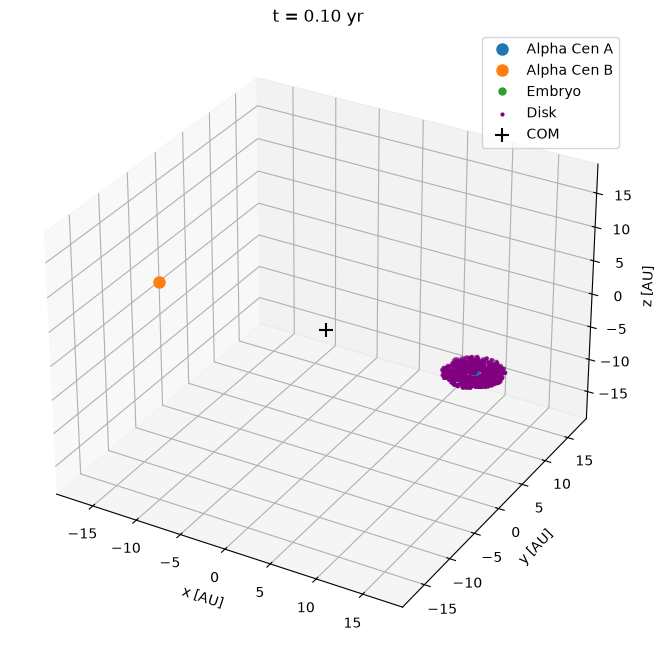

In [11]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.pyplot as plt
import numpy as np

color_A = "tab:blue"
color_B = "tab:orange"
color_P = "tab:green"

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

all_x = np.concatenate([xA, xB, xP])
all_y = np.concatenate([yA, yB, yP])
all_z = np.concatenate([zA, zB, zP])

extent = max(
    np.max(np.abs(all_x)),
    np.max(np.abs(all_y)),
    np.max(np.abs(all_z))
)

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.set_zlim(-extent, extent)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")

starA, = ax.plot([], [], [], "o", ms=8, color=color_A, label="Alpha Cen A")
starB, = ax.plot([], [], [], "o", ms=8, color=color_B, label="Alpha Cen B")
planet, = ax.plot([], [], [], "o", ms=5, color=color_P, label="Embryo")
disk_scatter = ax.scatter([], [], [], s=4, color="purple", label="Disk")

trailA, = ax.plot([], [], [], lw=1, color=color_A)
trailB, = ax.plot([], [], [], lw=2, color=color_B)
trailP, = ax.plot([], [], [], lw=0.5, color=color_P)

ax.scatter(0, 0, 0, c="k", marker="+", s=100, label="COM")

ax.legend()

nframes = len(time_saved)

def update(frame):

    if frame % 50 == 0:
        print(
            f"\rRendering frame {frame+1}/{nframes} "
            f"({100*(frame+1)/nframes:.1f}%)",
            end=""
        )

    starA.set_data([xA[frame]], [yA[frame]])
    starA.set_3d_properties([zA[frame]])

    starB.set_data([xB[frame]], [yB[frame]])
    starB.set_3d_properties([zB[frame]])

    planet.set_data([xP[frame]], [yP[frame]])
    planet.set_3d_properties([zP[frame]])

    disk_scatter._offsets3d = (
        xD[frame],
        yD[frame],
        zD[frame]
    )

    history = 500
    start = max(0, frame - history)

    trailA.set_data(xA[start:frame+1], yA[start:frame+1])
    trailA.set_3d_properties(zA[start:frame+1])

    trailB.set_data(xB[start:frame+1], yB[start:frame+1])
    trailB.set_3d_properties(zB[start:frame+1])

    trailP.set_data(xP[start:frame+1], yP[start:frame+1])
    trailP.set_3d_properties(zP[start:frame+1])

    ax.set_title(f"t = {time_saved[frame]:.2f} yr")

    return (
        starA,
        starB,
        planet,
        disk_scatter,
        trailA,
        trailB,
        trailP
    )

anim = FuncAnimation(
    fig,
    update,
    frames=nframes,
    interval=20,
    blit=False
)

print("\nSaving video...")

writer = FFMpegWriter(
    fps=30,
    bitrate=4000
)

anim.save(
    "alpha_centauri_disk.mp4",
    writer=writer
)

print("Done.")